In [1]:
#@title Imports and hyperparameters
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy
from scipy.stats import ttest_rel
from tqdm import tqdm

import datasets
from helpers import gather_seeds, simulate_models, reach_stats, dict_reach_stats, \
                    dict_to_csv, array_to_heatmap
from helpers_exploration import calc_exploration_metrics, \
                                region_counts_histogram, region_counts_histogram_df
from plots import plot_cov_hull, dataset_cmaps, plot_reference_lines, add_border_and_ticks
from metrics import calc_all_metric
#from wasserstein_distance import calc_all_wds

os.makedirs('csv', exist_ok=True)

# Hyperparameters
unmask_every = 3
sigma_s = sigma_r = 1
T_multiplier = 4
radius = 0.2 # radius within which endpoints have been "reached". NOTE: changed from 0.1!
dataset = 'triangle'

param_combos = []
for lambda_v in [1, 0.9, 0.8, 0.7]:
    for b_a in [0, 0.01, 0.02]:
        param_combos.append(
            {'sigma_r': sigma_r, 'lambda_v': lambda_v, 'b_a': b_a}
        )

In [2]:
endpoints = datasets.triangle_vertices_and_mus()[-1]
groups = 6

# Gather seeds
seeds = gather_seeds(f'{dataset}_dataset', f'unmask_every_{unmask_every}')
# other seeds have bad or weird replay
#seeds = [0, 1, 2, 5, 6, 7, 12, 15, 19]
#seeds = [0, 1, 2, 5, 6, 7, 12, 19]
#seeds = [0, 1, 2, 5, 6, 7, 8, 12, 19]
seeds = [0, 1, 2, 5, 6, 7, 8, 12, 17, 19]
#seeds = [0, 1, 2, 5, 6, 7, 8, 12, 17, 18, 19]
seeds = list(set(seeds)) # keep only unique values, since there are noleak seeds, too
print(seeds), len(seeds)

[0, 1, 2, 5, 6, 7, 8, 12, 17, 19]


(None, 10)

In [3]:
# Simulate models
# replays is a dictionary of Tensors, awake_trajectories is one Tensor
replays, awake_trajectories = simulate_models(
    sigma_s=0.05, hidden_dim=40, T_multiplier=T_multiplier,
    param_combos=param_combos, seeds=seeds,
    model_dir='results', model_prefix=f'{dataset}_dataset__unmask_every_{unmask_every}',
    plaus=True
)

  0%|                                                    | 0/10 [00:00<?, ?it/s]

Running sample_plaus() instead of rnn.sample()


 10%|████▍                                       | 1/10 [00:01<00:13,  1.46s/it]

Running sample_plaus() instead of rnn.sample()


 20%|████████▊                                   | 2/10 [00:02<00:10,  1.35s/it]

Running sample_plaus() instead of rnn.sample()


... (11 outputs left out)

Running sample_plaus() instead of rnn.sample()


 90%|███████████████████████████████████████▌    | 9/10 [00:11<00:01,  1.29s/it]

Running sample_plaus() instead of rnn.sample()


100%|███████████████████████████████████████████| 10/10 [00:13<00:00,  1.31s/it]


100%|███████████████████████████████████████████| 12/12 [00:54<00:00,  4.58s/it]


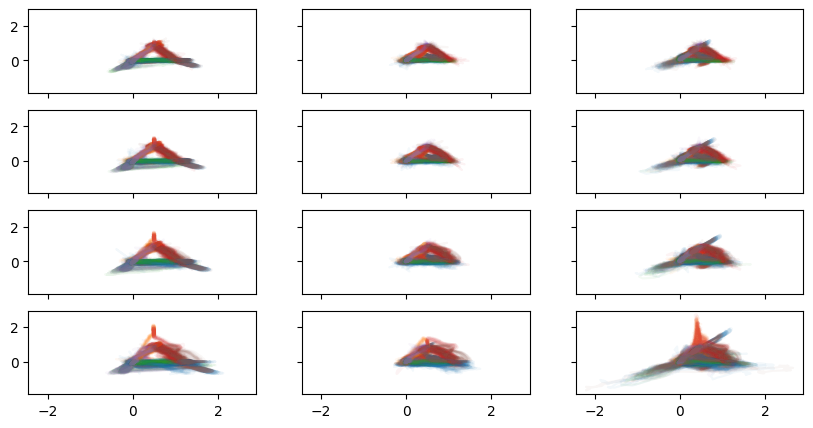

In [4]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:,g,j,:,0], x_hat[:,g,j,:,1], c=f'C{g}', alpha=0.05)

100%|███████████████████████████████████████████| 12/12 [00:18<00:00,  1.52s/it]


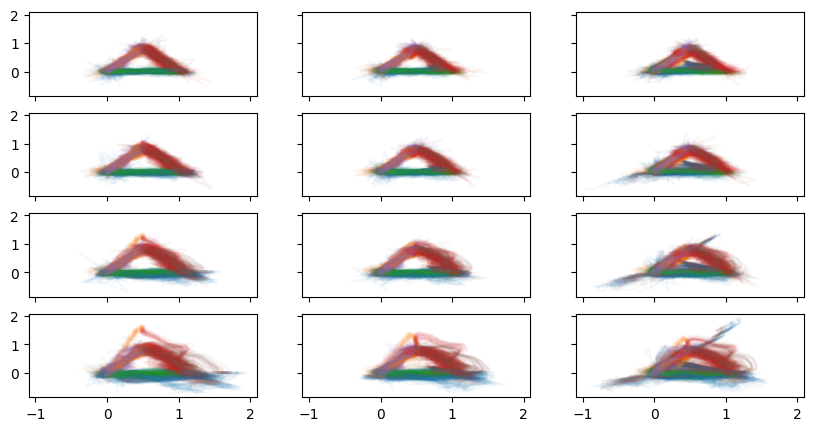

In [5]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:100,g,j,:,0], x_hat[:100,g,j,:,1], c=f'C{g}', alpha=0.05)

In [6]:
every_region_count_value, region_count_avgs, \
every_distance, distance_avgs = calc_exploration_metrics(dataset, replays)

df_rcnt_avg = dict_to_csv(region_count_avgs, col_param="b_a",
                          path=f"csv/plaus_exploration_{dataset}_region_counts_avg.csv")
df_dist_avg = dict_to_csv(distance_avgs, col_param="b_a",
                          path=f"csv/plaus_exploration_{dataset}_distances_avg.csv")

In [7]:
print("Exploration p-values:")
p = {k: ttest_rel(every_region_count_value[str(param_combos[0])].flatten(),
                  v.flatten()).pvalue
     for (k,v) in every_region_count_value.items()}
p

Exploration p-values:


{"{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0}": nan,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.01}": 2.5485887832916598e-70,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.02}": 1.9573168237945236e-100,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0}": 0.013089007720379785,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.01}": 1.4759291067034851e-65,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.02}": 6.247790830241529e-109,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0}": 2.7558746257008207e-05,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.01}": 5.469575233322633e-68,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.02}": 1.2783320317043051e-126,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0}": 4.521253271780194e-10,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.01}": 5.832551046807325e-75,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.02}": 3.410470777185342e-148}

In [8]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{}

In [9]:
print("Distance-traveled p values:")
p = {k: ttest_rel(every_distance[str(param_combos[0])].flatten(), v.flatten()).pvalue
     for (k,v) in every_distance.items()}
p

Distance-traveled p values:


{"{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0}": nan,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.01}": 1.5645543049296397e-52,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.02}": 2.365105565134576e-142,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0}": 0.0045889166836257725,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.01}": 1.508975699237475e-70,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.02}": 3.683896867319568e-155,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0}": 2.3801660359111217e-25,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.01}": 9.63438375433685e-105,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.02}": 1.1148147027940002e-179,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0}": 4.410011081481298e-99,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.01}": 4.897421657107332e-150,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.02}": 3.828252292440109e-166}

In [10]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{}

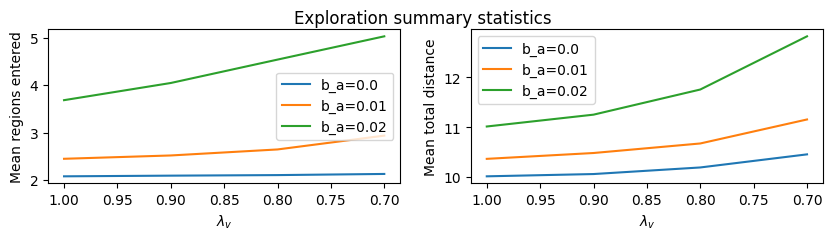

In [11]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,2))
for i, b_a in enumerate([0.0, 0.01, 0.02]):
    x = df_rcnt_avg['lambda_v']
    label = f'{b_a=}'
    axs[0].plot(x, df_rcnt_avg[label], label=label)
    axs[1].plot(x, df_dist_avg[f'{b_a=}'], label=label)
for ax in axs:
    ax.legend()
    ax.xaxis.set_inverted(True)
    ax.set(xlabel='$\lambda_v$')
axs[0].set(ylabel='Mean regions entered')
axs[1].set(ylabel='Mean total distance')
fig.suptitle('Exploration summary statistics')
fig.show()

In [12]:
# flatten replays: combine the len(seeds) and num samples dimensions together.
replays = {k: v.flatten(start_dim=2, end_dim=3) for (k,v) in replays.items()}
# calculate reach time statistics
reach_times, rt_meds, rt_avgs, rt_stds, failure_rates = \
    dict_reach_stats(replays, endpoints, radius)
awake_rts, awake_rt_med, awake_rt_avg, awake_rt_std, _ = \
    reach_stats(awake_trajectories, endpoints, radius)
# reshape medians and avgs for plotting
delta_arrays = {
    'median':  (np.array(list(rt_meds.values())).reshape(4,3) / awake_rt_med - 1) * 100,
    'average': (np.array(list(rt_avgs.values())).reshape(4,3) / awake_rt_avg - 1) * 100
}

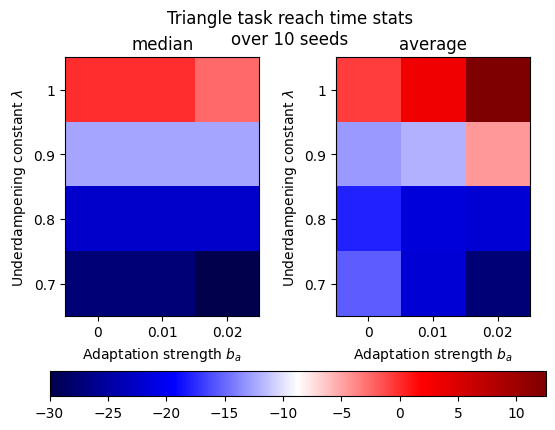

In [19]:
cmap = plt.cm.seismic #c = 'seismic'
fig, axs = plt.subplots(nrows=1, ncols=len(delta_arrays))
vmin = min([a.min() for a in delta_arrays.values()])
vmax = max([a.max() for a in delta_arrays.values()])
for i,(k,v) in enumerate(delta_arrays.items()):
    im = axs[i].imshow(v, cmap=cmap, vmin=vmin, vmax=vmax)
    axs[i].set(title=k,
               xlabel='Adaptation strength $b_a$',
               ylabel='Underdampening constant $\lambda$',
               xticks=[0,1,2], xticklabels=[0,0.01,0.02],
               yticks=[0,1,2,3], yticklabels=[1,0.9,0.8,0.7])
fig.colorbar(im, ax=axs.ravel().tolist(), location='bottom')
fig.suptitle(f'Triangle task reach time stats\nover {len(seeds)} seeds');

In [14]:
# save results
array_to_heatmap(delta_arrays['median'],  f'csv/plaus_med_rt_heatmap_{dataset}.txt')
array_to_heatmap(delta_arrays['average'], f'csv/plaus_avg_rt_heatmap_{dataset}.txt');

Make sure to add newlines before plotting in TikZ
Make sure to add newlines before plotting in TikZ


In [15]:
wds = calc_all_metric(replays, awake_trajectories, 'wd')
wds = dict_to_csv(wds, col_param='b_a', path=f'csv/plaus_wd_{dataset}.csv');

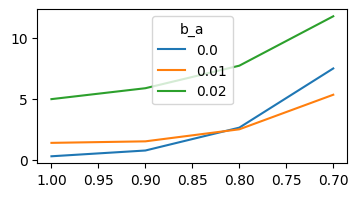

In [16]:
plt.figure(figsize=(4,2))
for b_a in [0.0, 0.01, 0.02]:
    plt.plot(wds['lambda_v'], wds[f'b_a={b_a}'], label=b_a)
plt.legend(title='b_a')
plt.gca().xaxis.set_inverted(True)

### additional plots

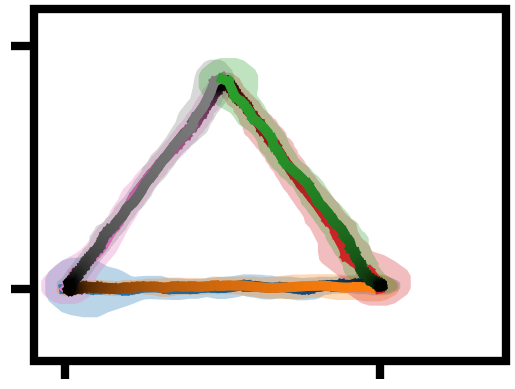

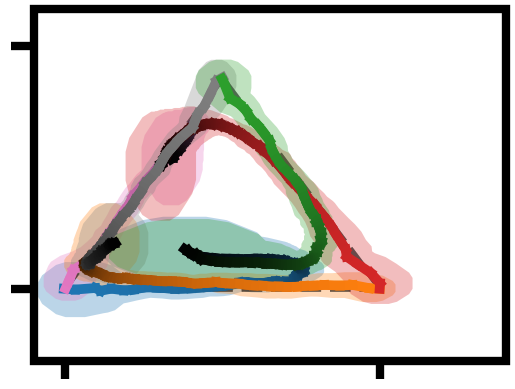

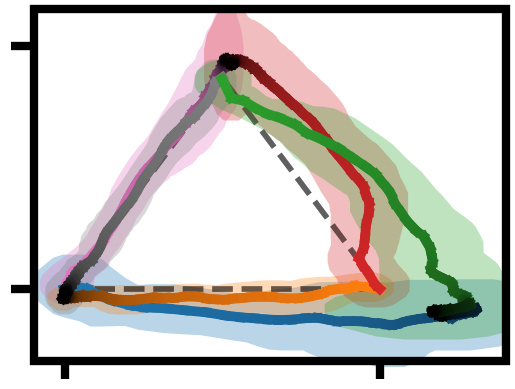

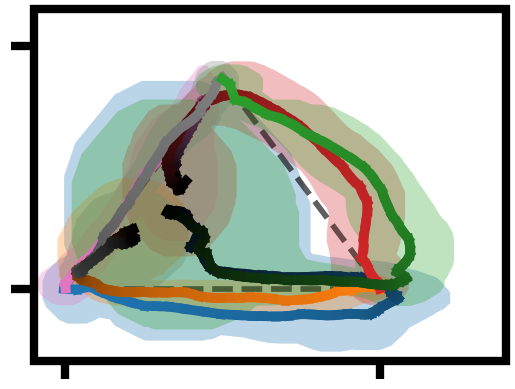

In [31]:
T_awake = len(awake_trajectories)
cmaps = dataset_cmaps('triangle')
xlim = (-0.1, 1.4)
ylim = (-0.3, 1.15)

for lambda_v in [1, 0.7]:
    for b_a in [0, 0.02]:
        fig, ax = plt.subplots(dpi=100)
        ax.axis('off')
        ax.set(xlim=xlim, ylim=ylim)

        x_hat = replays[str({'sigma_r': sigma_r, 'lambda_v': lambda_v, 'b_a': b_a})]
        for group in range(groups):
            group_hat = x_hat[:T_awake, group]
            plot_cov_hull(group_hat, ax=ax, color=cmaps[group](0), alpha=0.3, zorder=-1)
            plot_reference_lines(ax=ax, dataset='triangle', linestyle='dashed',
                                 color='black', alpha=0.15, zorder=-1, linewidth=4)
            mean = group_hat.mean(1) # mean trajectory
            for t in range(T_awake-1):
                ax.plot(mean[t:t+2,0], mean[t:t+2,1], c=cmaps[group](t/T_awake),
                        linewidth=7, zorder=1)

        add_border_and_ticks(ax, xlim, ylim)
        
        fig.savefig(f'figures/means/triangle_{lambda_v=},{b_a=}.png',
                    bbox_inches='tight', pad_inches=0)

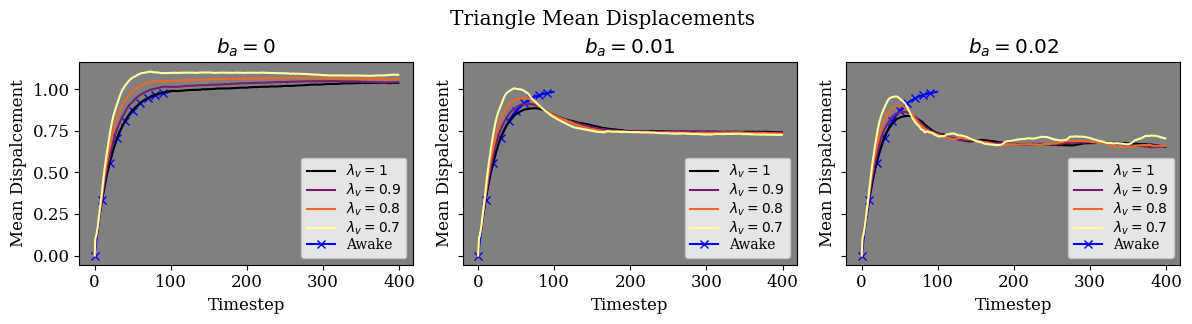

In [32]:
os.makedirs('figures/mean_displacements', exist_ok=True)
os.makedirs('figures/variance', exist_ok=True)

from cycler import cycler
cmap = plt.get_cmap('inferno')
plt.rc('axes', prop_cycle=cycler(color=cmap(np.linspace(0, 1, 4)))) # 4 lines

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12 # previously 10


fig, axs = plt.subplots(nrows=1, ncols=3, sharex=True, sharey=True, figsize=(12,3.5))
for k, v in list(replays.items()):
    k = eval(k)
    rs = v.flatten(1,-2) # first timestep = time, last timestep = dimension (2)
    ax = axs[[0, 0.01, 0.02].index(k['b_a'])]
    ax.set(title=f'$b_a = {k["b_a"]}$')
    ax.plot((rs - rs[0:1]).square().sum(-1).sqrt().mean(1),
            label=f"$\lambda_v={k['lambda_v']}$")

for ax in axs:
    ax.plot((awake_trajectories.flatten(1,-2)[:] - \
              awake_trajectories.flatten(1,-2)[0:1]).square().sum(-1).sqrt().mean(1),
             c='blue', marker='x', markevery=10, zorder=-1, label='Awake')
    ax.legend(loc='lower right', fancybox=True, fontsize=10, ncol=1, labelspacing=0.1)
    ax.set(facecolor='gray', xlabel='Timestep', ylabel='Mean Dispalcement')
fig.suptitle('Triangle Mean Displacements', y=0.92)
fig.tight_layout()
fig.savefig('figures/mean_displacements/triangle_md.pdf', bbox_inches='tight')

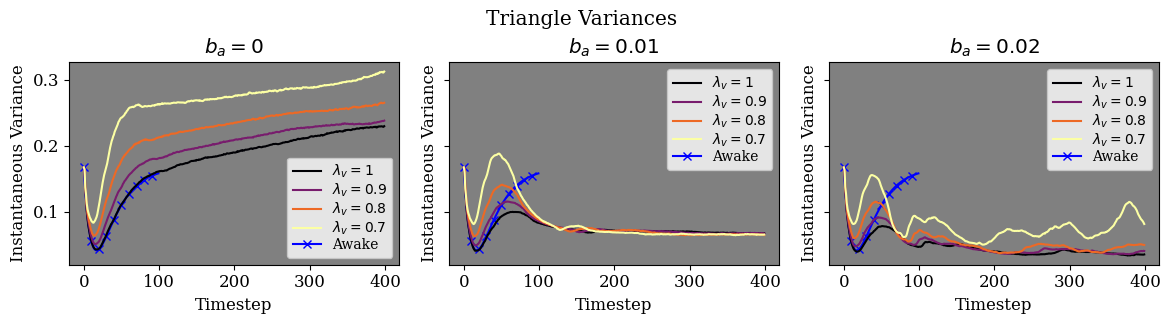

In [33]:
fig, axs = plt.subplots(nrows=1, ncols=3, sharex=True, sharey=True, figsize=(12,3.5))
for k, v in list(replays.items()):
    k = eval(k)
    rs = v.flatten(1,-2) # first timestep = time, last timestep = dimension (2)
    ax = axs[[0, 0.01, 0.02].index(k['b_a'])]
    ax.set(title=f'$b_a = {k["b_a"]}$')
    ax.plot(rs.var(1).mean(-1), label=f"$\lambda_v={k['lambda_v']}$")

for ax in axs:
    ax.plot(awake_trajectories.flatten(1,-2).var(1).mean(-1),
            c='blue', marker='x', markevery=10, zorder=-1, label='Awake')
    ax.set(facecolor='gray', xlabel='Timestep', ylabel='Instantaneous Variance')
    ax.legend(fancybox=True, fontsize=10, ncol=1, labelspacing=0.1)
    
fig.suptitle('Triangle Variances', y=0.92)
fig.tight_layout()
fig.savefig('figures/variance/triangle_var.pdf', bbox_inches='tight')